<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 08: Housing Price Prediction




The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [ ]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: dc2G6Vty3juG39GOv7pX1zIFOH+qrhKsu5q3yFlmokZ7ERn/vK2h/wB8VKRlQtSmuojkiVFjd8Q=
x-amz-request-id: NS740NEJ4N4NXNFS
Server: AmazonS3
Date: Wed, 28 Oct 2026 02:49:55 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [ ]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Help investors evaluate whether what features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [ ]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [ ]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [ ]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [ ]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [ ]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [ ]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [ ]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [ ]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [ ]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [ ]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [ ]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [ ]:
# Define the name of the feature columns to work with them independently (all floats are features)
# Select all float columns
feature_cols = df.select_dtypes(include=['float']).columns

# Drop the target column from the feature column names
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols]

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [ ]:
# Look for nulls in the features (dropping rows if 20% nulls or under) - 17% is the highest proportion of nulls in 'Lot Frontage'
(df[feature_cols].isnull().sum() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Half Bath,0.075844
Bsmt Full Bath,0.075844
BsmtFin SF 1,0.037922
BsmtFin SF 2,0.037922
Total Bsmt SF,0.037922
Bsmt Unf SF,0.037922
Garage Cars,0.037922


#### Identifier Columns

In [ ]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [ ]:
# See proportion of unique values in the feature columns
(df[feature_cols].nunique() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Bsmt Unf SF,40.955631
Total Bsmt SF,37.959803
BsmtFin SF 1,35.456959
Garage Area,21.843003
Mas Vnr Area,16.116799
BsmtFin SF 2,9.594236
Lot Frontage,4.778157
Garage Yr Blt,3.868032
Garage Cars,0.227531
Bsmt Full Bath,0.151688


In [ ]:
# See for all data - PID is an identifier column
(df.nunique() / df.shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Bsmt Half Bath,0.113766
Paved Drive,0.113766
Street,0.075844
Alley,0.075844


In [ ]:
# See the data types of the features - continuous are good for linear regression
df[feature_cols].dtypes

,0
Lot Frontage,float64
Mas Vnr Area,float64
BsmtFin SF 1,float64
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64
Bsmt Half Bath,float64
Garage Yr Blt,float64
Garage Cars,float64


In [ ]:
# See the data types of the target - continuous are good for linear regression
df[target_col].dtypes

dtype('int64')

### Backup #1

In [ ]:
# Make a backup
df_bak1 = df.copy()

In [ ]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

Feature column containing 17% nulls, so drop those rows in our dataset.

In [ ]:
# Drop null rows referencing the feature column
df = df.dropna(subset=feature_cols)

In [ ]:
# Verify rows dropped
df.shape

(2033, 81)

In [ ]:
# Verify no nulls in feature columns
df[feature_cols].isnull().sum()

,0
Lot Frontage,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0
Bsmt Unf SF,0
Total Bsmt SF,0
Bsmt Full Bath,0
Bsmt Half Bath,0
Garage Yr Blt,0
Garage Cars,0


### Backup #2

In [ ]:
# Make a backup
df_bak2 = df.copy()

In [ ]:
# Restore from backup
df = df_bak2.copy()

### Cleaned Data Frame

In [ ]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [ ]:
# Verify the working data frame
df_clean

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2028,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2029,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2030,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2031,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


## EDA (Exploratory Data Analysis)

### Feature Selection

In [ ]:
# split into Target and Features
X_all_features = df_clean.drop(target_col, axis = 1)
y_target = df_clean[target_col]

In [ ]:
# Perform CV
n = 500
results = np.zeros(n)
for idx in range(n):
  X_train, X_test, y_train, y_test = train_test_split(X_all_features,y_target,test_size=0.25)
  model = LinearRegression()
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

print(f"CV RMSE: {results.mean().round(2)}")
print(f"Number of Predictors: {len(X_all_features.columns)}")

CV RMSE: 48881.16
Number of Predictors: 11


#### Correlation with the target

In [ ]:
# Correlation ranking with (corr of features with the target)
corr_mat = df_clean.corr()[target_col].abs().sort_values(ascending = False)
corr_mat

,SalePrice
SalePrice,1.000000
Garage Cars,0.657323
Total Bsmt SF,0.646068
Garage Area,0.637670
Garage Yr Blt,0.547303
Mas Vnr Area,0.523401
BsmtFin SF 1,0.434640
Lot Frontage,0.353584
Bsmt Full Bath,0.288551
Bsmt Unf SF,0.191868


##### Correlation bar graph


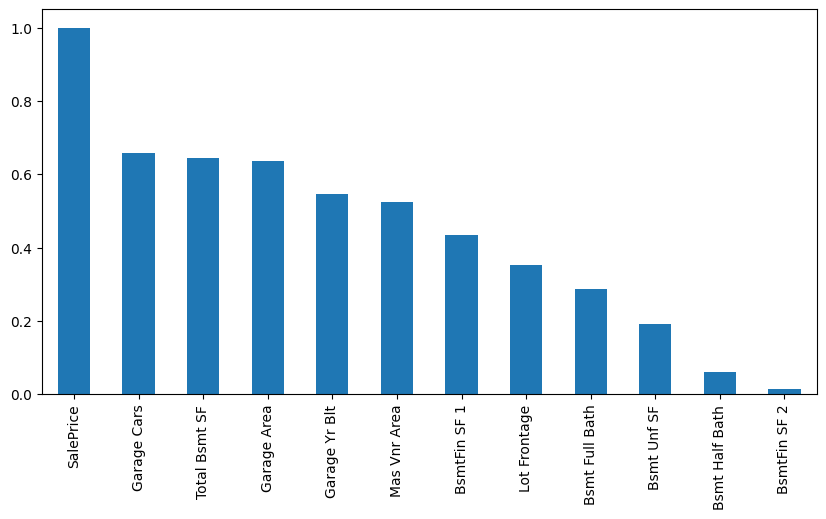

In [ ]:
# Plot the correlation
df_clean.corr()[target_col].abs().sort_values(ascending = False).plot(kind = 'bar', figsize = (10,5)) ;

In [ ]:
# Selected 3 features with highest correlation with the target
feature_cols = ['Garage Area','Total Bsmt SF','Garage Yr Blt']

### Working Data Frame

In [ ]:
df_work = pd.concat([df_clean[target_col], df_clean[feature_cols]], axis=1).reset_index(drop=True)

In [ ]:
df_work

,SalePrice,Garage Area,Total Bsmt SF,Garage Yr Blt
0,115400,440.0,1005.0,1964.0
1,90000,516.0,0.0,1967.0
2,141000,544.0,780.0,1979.0
3,254000,592.0,975.0,2000.0
4,155000,576.0,560.0,1971.0
...,...,...,...,...
2028,114500,528.0,816.0,1985.0
2029,162000,462.0,1054.0,1990.0
2030,211500,484.0,1226.0,1981.0
2031,165000,478.0,1064.0,1974.0


## Data Processing

Prepare Data Frame (Target and Features)

In [ ]:
# Define out the target and feature columns from our cleaned working data frame
df_work[feature_cols]
df_work[target_col]

#### Performance

##### Linear Regression

Multi Cross Validation

In [ ]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        df_work[feature_cols],
        df_work[[target_col]],
        test_size=0.25,
        random_state=None
    )

    # Create an empty LR model
    modelLR = LinearRegression()

    # Train ( fit ) the model
    modelLR.fit( (X_train), y_train)

    # Make predicitons using the model
    y_pred = modelLR.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.r2_score(y_test, y_pred)

results

array([0.59605597, 0.613007  , 0.55519968, 0.48770662, 0.60050469,
       0.61025808, 0.54354389, 0.5096406 , 0.62869012, 0.54090269,
       0.55918128, 0.62289267, 0.6162992 , 0.57735432, 0.44900265,
       0.56737543, 0.41340854, 0.57422348, 0.56415738, 0.55886759,
       0.61332113, 0.5965172 , 0.58093758, 0.60219201, 0.60034163,
       0.55771   , 0.60953068, 0.58503479, 0.58807873, 0.50590421,
       0.45708265, 0.58868178, 0.51546705, 0.53981858, 0.59289501,
       0.43480503, 0.63207186, 0.56219307, 0.47620496, 0.5799411 ,
       0.62643112, 0.59305028, 0.58773465, 0.44495549, 0.58015407,
       0.55107896, 0.57778464, 0.61868872, 0.47045927, 0.4885406 ,
       0.57930406, 0.60129616, 0.6009593 , 0.57509537, 0.46736281,
       0.61973372, 0.59055999, 0.58463106, 0.46399804, 0.53247295,
       0.53497723, 0.5650821 , 0.63997472, 0.57317447, 0.62212877,
       0.5784186 , 0.60272515, 0.455756  , 0.5635835 , 0.60264049,
       0.4724143 , 0.47767567, 0.6545999 , 0.57644768, 0.61375

''

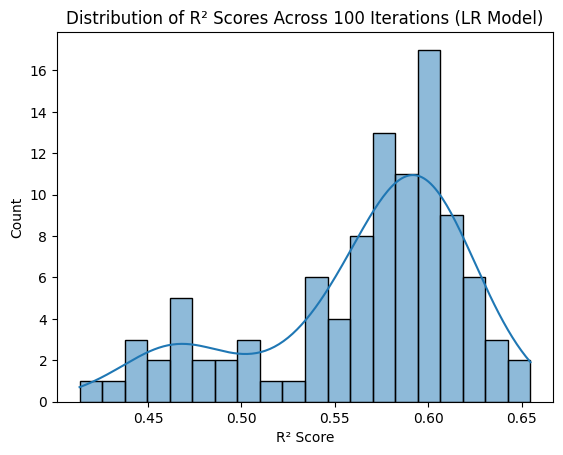

In [ ]:
# Display a histogram of the multi CV results
sns.histplot(results, kde=True, bins=20)
plt.title('Distribution of R² Scores Across 100 Iterations (LR Model)')
plt.xlabel('R² Score')
plt.ylabel('Count')
;

In [ ]:
# Linear Regression - prediction peformance stats
print("Mean R²:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum R²:", np.min(results))
print("Maximum R²:", np.max(results))

Mean R²: 0.5654691054202665
Standard deviation: 0.0546976170895521
Minimum R²: 0.41340853612030326
Maximum R²: 0.6545998954566484


## Data Visualization

#### Residual Analysis

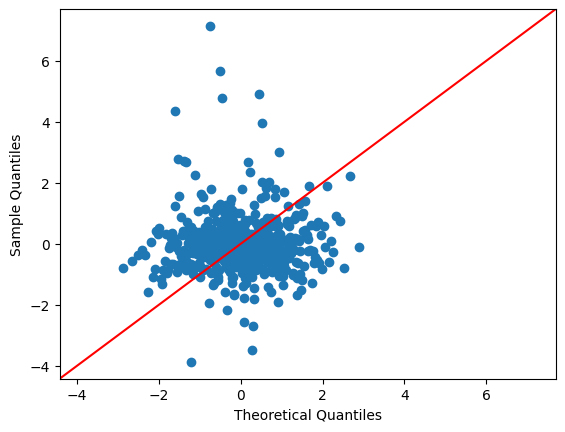

In [ ]:
# QQ Plot - Residuals are not normally distributed
res = y_test[['SalePrice']] - y_pred
sm.qqplot(res, fit=True, line="45") ;

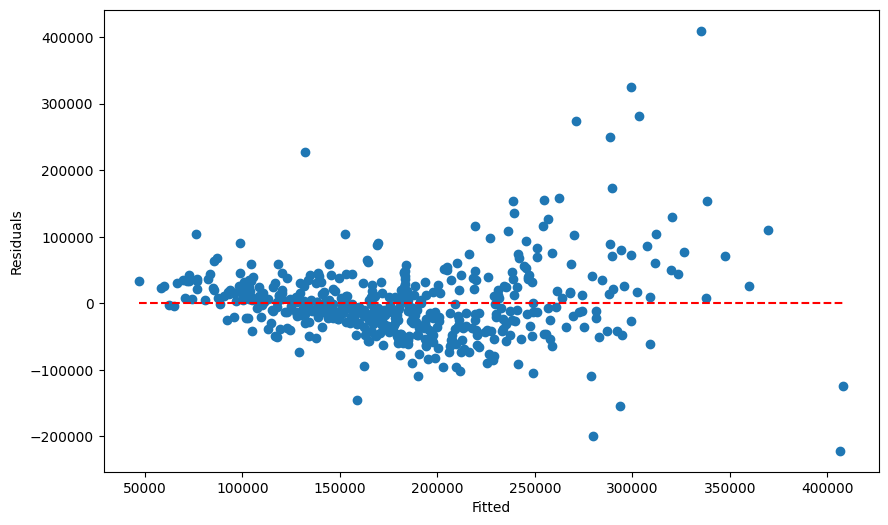

In [ ]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

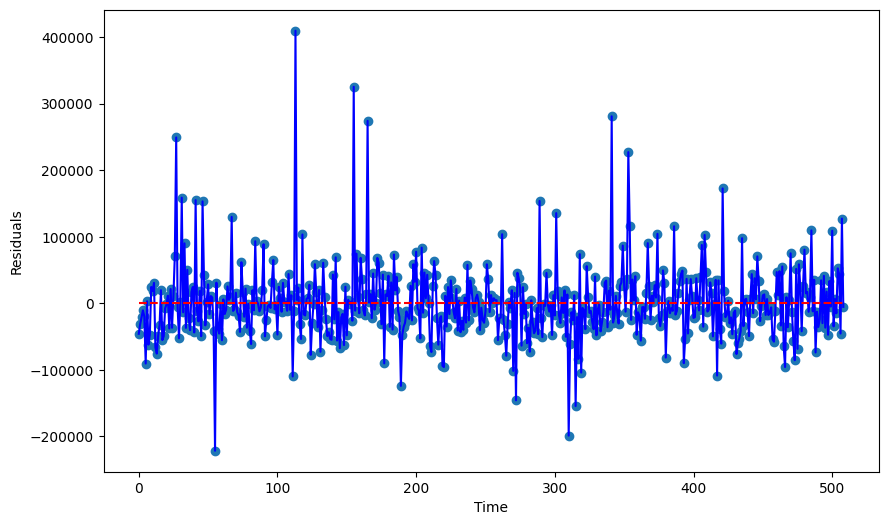

In [ ]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

In [ ]:
# Linear Regression - prediction peformance stats
print("Mean R²:", np.mean(results))
print("Standard deviation:", np.std(results))
print("Minimum R²:", np.min(results))
print("Maximum R²:", np.max(results))

Mean R²: 0.5654691054202665
Standard deviation: 0.0546976170895521
Minimum R²: 0.41340853612030326
Maximum R²: 0.6545998954566484


## Communication of Results

#### Conclusion

Mean R² for Linear Regression Model: 0.5654691054202665

Selecting these three features highly correlated with the target, the model has performed the worst out of all the passes.

#### Future Work
- Try a different model
- Try additional features